# Multiclass Injury Severity Prediction in Highway and Non-Highway Crashes
**Dataset:** UK Stats19 (Proxy Data for Pipeline Proof of Concept)

This notebook demonstrates the end-to-end Proof of Concept (PoC) machine learning pipeline. As the Bangladesh dataset is currently being procured, this proxy data allows us to validate our preprocessing, data segmentation, class balancing (SMOTE), and baseline modeling architecture. This notebook aligns with the core methodology by training and evaluating Logistic Regression, Random Forest, XGBoost, LightGBM, and CatBoost models, and incorporates SHAP explainability.

### 1. Importing Libraries
Loading the necessary libraries for data manipulation, preprocessing, modeling, cross-validation, and evaluation matrix (including ROC-AUC and SHAP).

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, label_binarize
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, f1_score

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from imblearn.over_sampling import SMOTE

import shap


### 2. Data Loading & Multiclass Target Mapping
We load the dataset and map the target variable (`Accident_Severity`) to our proposed methodology:
* **0 = Fatal** (Mapped from 1)
* **1 = Grievous** (Proxy: 'Serious' in Stats19, Mapped from 2)
* **2 = Simple** (Proxy: 'Slight' in Stats19, Mapped from 3)

Note: Target is mapped to 0, 1, 2 to ensure compatibility with XGBoost and LightGBM APIs.

In [2]:
# Load the proxy dataset
df = pd.read_csv('UKaccident/Accidents0515.csv', low_memory=False)

# The Stats19 dataset uses 1=Fatal, 2=Serious, 3=Slight.
# We are aligning this with our research taxonomy: 0=Fatal, 1=Grievous, 2=Simple
severity_mapping = {1: '1 - Fatal', 2: '2 - Grievous', 3: '3 - Simple'}
df['Severity_Label'] = df['Accident_Severity'].map(severity_mapping)

# Map to 0-indexed values for XGBoost compatibility
df['Accident_Severity_Mapped'] = df['Accident_Severity'] - 1

print(f"Dataset shape: {df.shape}")
print("\nTarget Variable Distribution:")
print(df['Severity_Label'].value_counts())

Dataset shape: (1780653, 34)

Target Variable Distribution:
Severity_Label
3 - Simple      1515575
2 - Grievous     242080
1 - Fatal         22998
Name: count, dtype: int64


### 3. Exploratory Data Analysis (EDA)
Visualizing the class distribution to highlight the extreme class imbalance typically found in crash data, justifying our use of SMOTE later in the pipeline.

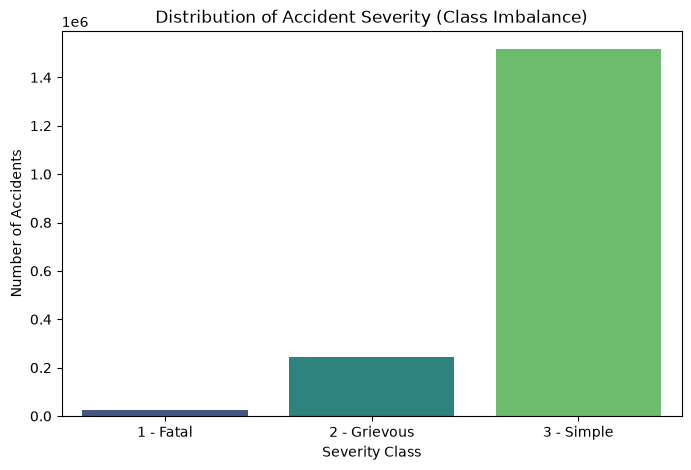

In [3]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Severity_Label', order=['1 - Fatal', '2 - Grievous', '3 - Simple'], palette='viridis')
plt.title("Distribution of Accident Severity (Class Imbalance)")
plt.xlabel("Severity Class")
plt.ylabel("Number of Accidents")
plt.show()

### 4. Data Segmentation: Highway vs. Non-Highway
Following the research methodology, we split the dataset based on the `Road_Type` column. According to UK Stats19 data dictionary, `3` corresponds to 'Dual carriageway'. We'll use this as a proxy for Highway conditions.

**Note:** To ensure rapid execution for this PoC presentation, we are utilizing a **20% random sample** of the highway data.

In [4]:
# Create the segmentation column
# Road_Type == 3 indicates 'Dual carriageway'
df['Is_Highway'] = np.where(df['Road_Type'] == 3, 'Highway', 'Non-Highway')

# Segment the data
df_highway_full = df[df['Is_Highway'] == 'Highway'].copy()
df_non_highway = df[df['Is_Highway'] == 'Non-Highway'].copy()

print(f"Total Highway Crashes: {df_highway_full.shape[0]}")
print(f"Non-Highway Crashes: {df_non_highway.shape[0]}")

# 20% Random Sampling for fast PoC execution
df_highway = df_highway_full.sample(frac=0.2, random_state=42).copy()
print(f"\nSampled Highway Crashes for PoC (20%): {df_highway.shape[0]}")

Total Highway Crashes: 262950
Non-Highway Crashes: 1517703

Sampled Highway Crashes for PoC (20%): 52590


### 5. Data Preprocessing
Dropping minimal missing values for execution speed and applying one-hot encoding to our categorical variables.

In [5]:
# Select a subset of features for the PoC pipeline
features = ['Day_of_Week', 'Weather_Conditions', 'Road_Surface_Conditions', 'Light_Conditions', 'Speed_limit']

# Replace -1 (missing data in Stats19) with NaN
df_highway.replace(-1, np.nan, inplace=True)

# Drop NaNs to ensure a clean pipeline execution for PoC
df_highway.dropna(subset=['Accident_Severity_Mapped'] + features, inplace=True)

X = df_highway[features]
y = df_highway['Accident_Severity_Mapped'] # Target is 0, 1, 2

# Define categorical and numerical columns
categorical_cols = ['Day_of_Week', 'Weather_Conditions', 'Road_Surface_Conditions', 'Light_Conditions']
numerical_cols = ['Speed_limit']

# Preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ])

X_processed = preprocessor.fit_transform(X)
print(f"Shape of processed feature matrix: {X_processed.shape}")

Shape of processed feature matrix: (52548, 27)


### 6. Stratified Train/Test Split & SMOTE
We apply a stratified split to preserve the distribution of classes in our test set. We then apply SMOTE **only** to the training data to prevent data leakage, successfully resolving the class imbalance for model training.

In [6]:
# 80/20 Stratified Split
X_train, X_test, y_train, y_test = train_test_split(
    X_processed, y, test_size=0.2, random_state=42, stratify=y
)

print("Class distribution BEFORE SMOTE (Training Set):")
print(y_train.value_counts().sort_index())

# Apply SMOTE to training data
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("\nClass distribution AFTER SMOTE (Training Set):")
print(y_train_smote.value_counts().sort_index())

Class distribution BEFORE SMOTE (Training Set):
Accident_Severity_Mapped
0      750
1     5051
2    36237
Name: count, dtype: int64

Class distribution AFTER SMOTE (Training Set):
Accident_Severity_Mapped
0    36237
1    36237
2    36237
Name: count, dtype: int64


### 7. Training, Hyperparameter Tuning & Evaluation Matrix
We train the suite of machine learning models specified in Section 5.1.1: Logistic Regression, Random Forest, XGBoost, LightGBM, and CatBoost. 

For CatBoost, we demonstrate the cross-validation and hyperparameter tuning methodology using `RandomizedSearchCV`.

The evaluation matrix includes F1-score, Precision, Recall, Confusion Matrix, and ROC-AUC (OvR).

Training Logistic Regression (Baseline)...



--- Evaluation Matrix: Logistic Regression (Baseline) ---
              precision    recall  f1-score   support

   Fatal (0)       0.03      0.60      0.06       187
Grievous (1)       0.13      0.21      0.16      1263
  Simple (2)       0.88      0.49      0.63      9060

    accuracy                           0.46     10510
   macro avg       0.35      0.43      0.28     10510
weighted avg       0.78      0.46      0.56     10510

ROC-AUC (Weighted, OvR): 0.5669


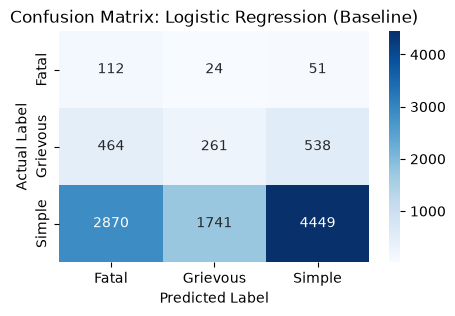

Training Random Forest...



--- Evaluation Matrix: Random Forest ---
              precision    recall  f1-score   support

   Fatal (0)       0.03      0.42      0.06       187
Grievous (1)       0.16      0.17      0.16      1263
  Simple (2)       0.88      0.64      0.74      9060

    accuracy                           0.58     10510
   macro avg       0.36      0.41      0.32     10510
weighted avg       0.78      0.58      0.66     10510

ROC-AUC (Weighted, OvR): 0.5629


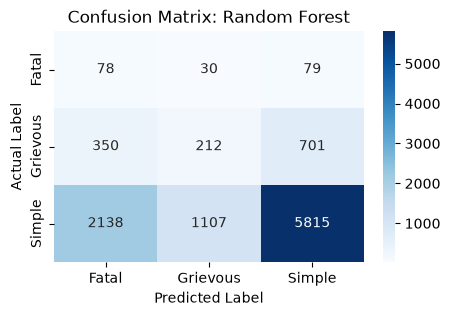

Training XGBoost...



--- Evaluation Matrix: XGBoost ---
              precision    recall  f1-score   support

   Fatal (0)       0.03      0.39      0.05       187
Grievous (1)       0.15      0.21      0.17      1263
  Simple (2)       0.88      0.59      0.71      9060

    accuracy                           0.54     10510
   macro avg       0.35      0.40      0.31     10510
weighted avg       0.78      0.54      0.63     10510

ROC-AUC (Weighted, OvR): 0.5606


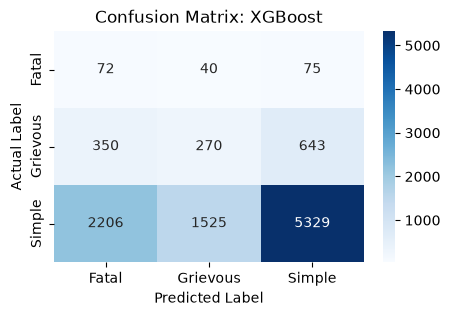

Training LightGBM...
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.008295 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 6040
[LightGBM] [Info] Number of data points in the train set: 108711, number of used features: 27
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612
[LightGBM] [Info] Start training from score -1.098612


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf

--- Evaluation Matrix: LightGBM ---
              precision    recall  f1-score   support

   Fatal (0)       0.03      0.41      0.05       187
Grievous (1)       0.15      0.22      0.18      1263
  Simple (2)       0.88      0.58      0.70      9060

    accuracy                           0.53     10510
   macro avg       0.35      0.41      0.31     10510
weighted avg       0.78      0.53      0.63     10510

ROC-AUC (Weighted, OvR): 0.5652


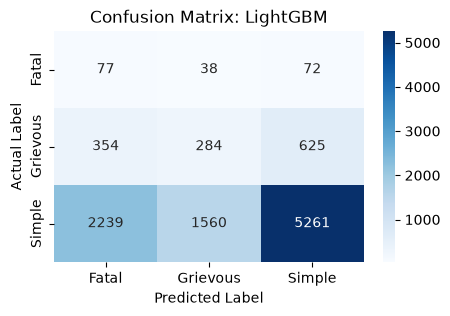

Training CatBoost (RandomizedSearchCV)...



--- Evaluation Matrix: CatBoost (RandomizedSearchCV) ---
              precision    recall  f1-score   support

   Fatal (0)       0.03      0.43      0.06       187
Grievous (1)       0.13      0.24      0.17      1263
  Simple (2)       0.88      0.57      0.69      9060

    accuracy                           0.52     10510
   macro avg       0.35      0.41      0.31     10510
weighted avg       0.78      0.52      0.62     10510

ROC-AUC (Weighted, OvR): 0.5642


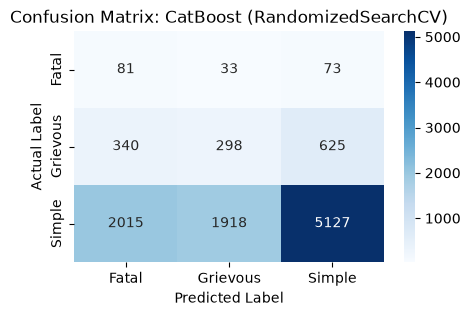

In [7]:
def train_and_evaluate(model, model_name):
    # Train
    print(f"Training {model_name}...")
    model.fit(X_train_smote, y_train_smote)
    
    # Predict
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test) if hasattr(model, 'predict_proba') else None
    
    # Evaluation Matrix
    print(f"\n--- Evaluation Matrix: {model_name} ---")
    print(classification_report(y_test, y_pred, target_names=['Fatal (0)', 'Grievous (1)', 'Simple (2)']))
    
    if y_prob is not None:
        y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
        roc_auc = roc_auc_score(y_test_bin, y_prob, average='weighted', multi_class='ovr')
        print(f"ROC-AUC (Weighted, OvR): {roc_auc:.4f}")
    
    # Confusion Matrix Visualization
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['Fatal', 'Grievous', 'Simple'], 
                yticklabels=['Fatal', 'Grievous', 'Simple'])
    plt.title(f"Confusion Matrix: {model_name}")
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')
    plt.show()
    return model

# Initialize models
log_reg = LogisticRegression(random_state=42, max_iter=1000)
rf = RandomForestClassifier(random_state=42, n_estimators=50, max_depth=10, n_jobs=-1)
xgb = XGBClassifier(random_state=42, n_estimators=50, max_depth=6, eval_metric='mlogloss')
lgbm = LGBMClassifier(random_state=42, n_estimators=50, max_depth=6)

# CatBoost Hyperparameter Tuning (Simplified for PoC)
cat_param_grid = {
    'iterations': [50, 100],
    'learning_rate': [0.05, 0.1],
    'depth': [4, 6]
}
catboost_base = CatBoostClassifier(random_seed=42, verbose=0, loss_function='MultiClass')
cat_search = RandomizedSearchCV(catboost_base, cat_param_grid, n_iter=3, cv=3, random_state=42, scoring='f1_weighted', n_jobs=-1)

# Execute Pipeline
train_and_evaluate(log_reg, "Logistic Regression (Baseline)")
train_and_evaluate(rf, "Random Forest")
train_and_evaluate(xgb, "XGBoost")
train_and_evaluate(lgbm, "LightGBM")
best_catboost = train_and_evaluate(cat_search, "CatBoost (RandomizedSearchCV)")

### 8. Explainable AI: Feature Importance (SHAP)
As outlined in Section 5.1.7 and 5.2.1, we utilize SHAP (SHapley Additive exPlanations) to interpret feature contributions in the prediction and overcome the 'black-box' limitations of the model.

The summary plot below visualizes the feature importance and impact on predicting the most critical injury class (Fatal).

Computing SHAP values for the best CatBoost Model...


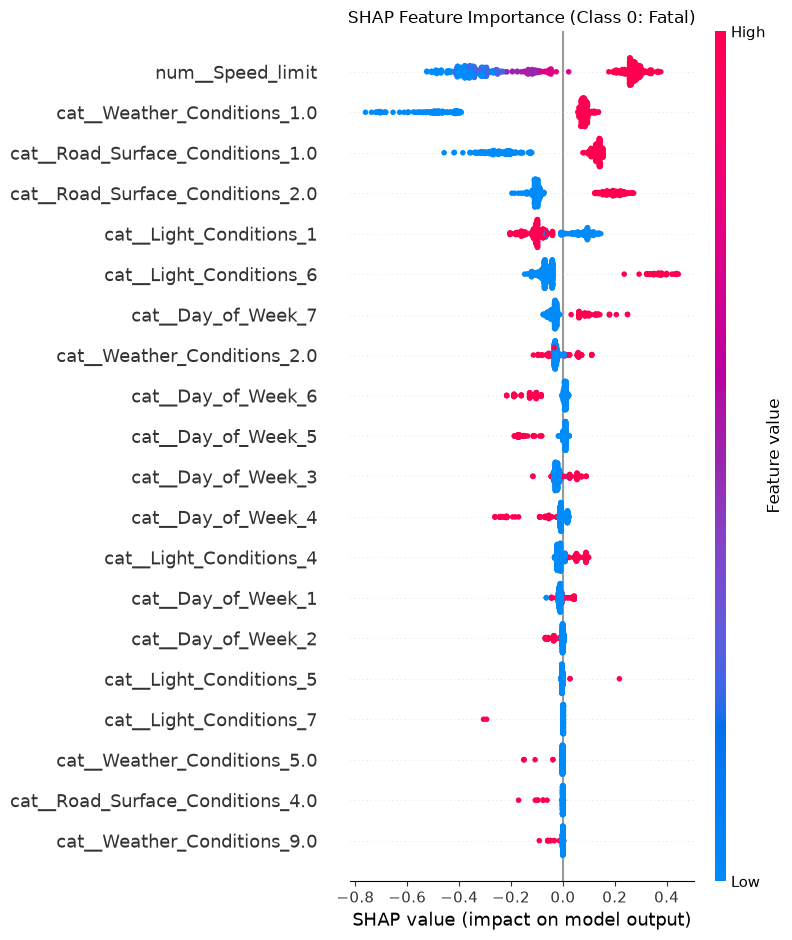

In [8]:
# Extract the best estimator from RandomizedSearchCV
final_catboost_model = best_catboost.best_estimator_

print("Computing SHAP values for the best CatBoost Model...")
# Get feature names from ColumnTransformer
feature_names = preprocessor.get_feature_names_out()

# Initialize SHAP explainer
explainer = shap.TreeExplainer(final_catboost_model)

# Calculate SHAP on a smaller subset of test data for speed
X_test_sample = X_test[:500] 
shap_values = explainer.shap_values(X_test_sample)

if isinstance(shap_values, list):
    shap_vals_class = shap_values[0]
elif len(shap_values.shape) == 3:
    shap_vals_class = shap_values[:, :, 0]
else:
    shap_vals_class = shap_values

if shap_vals_class.shape[1] == X_test_sample.shape[1] + 1:
    shap_vals_class = shap_vals_class[:, :-1]

plt.figure(figsize=(8, 6))
plt.title("SHAP Feature Importance (Class 0: Fatal)")
shap.summary_plot(shap_vals_class, X_test_sample, feature_names=feature_names, show=False)
plt.show()